# 90 Figures and facts of the study-plan report

This notebook draws the figures of the study-plan report `docs/reports/study_plan_20261015/report.pdf` and writes the facts that the report quotes.
- **Figures.** Each is drawn here and saved as `figures/Figure_NN_<topic>.pdf` and `.png` (300 dpi) in the report folder, in the style of the Imsil and Haenam reports: Helvetica, 8 pt, panel letters, closed frames.
- **Facts.** Every number in `report.tex` is a macro `\F{key}` defined in `facts.tex`, written here from `facts.json`. A fact is computed here from the project tables or quoted from the executed output of the notebook that measured it (a pattern that must match one value only). Each fact records its source.
- **Status facts** (download and pilot progress) are a snapshot taken when this notebook runs.

Nothing in the pipeline, the data or the catalogs is changed.

| Figure | Content | Made from |
|---|---|---|
| 1 | The sequence and the earlier relocation | NECIS domestic catalog, `registry/events.csv`, `gwangyang_pnplus` relocation |
| 2 | Station map | `detection/station_table/stations.csv`, `registry/streams.csv` |
| 3 | Stations and data per year | `docs/station_inventory/tables/stream_periods.csv`, KIGAM worklist |
| 4 | Completeness of the 2021 episode data | the continuous link tree `data/continuous/sds_links` |
| 5 | Sensor orientation | 33 national measurements, G2 measurements, `orientation_periods.csv` |
| 6 | Processing stages G0-G9 | stage status |

In [1]:
import os, sys, re, json, glob, hashlib, datetime, warnings
import numpy as np, pandas as pd
warnings.filterwarnings('ignore', category=FutureWarning)
ROOT = '/home/msseo/works/73.Gwangyang_sequence'; NBD = f'{ROOT}/notebooks'
REP = f'{ROOT}/docs/reports/study_plan_20261015'; FIG = f'{REP}/figures'; os.makedirs(FIG, exist_ok=True)
import pathlib
import matplotlib as mpl, matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib import font_manager as fm
from matplotlib.colors import ListedColormap, Normalize
from matplotlib.patches import FancyBboxPatch, Patch
pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 160)
# Helvetica as in the Haenam and Imsil summary reports (moho 24.Slip_inversion/pipeline/notebooks/nbfont.py, pasted verbatim without its docstrings):
# regular/bold/italic faces built from URW NimbusSans (metric-compatible Helvetica clone; has Greek and superscripts) renamed Helvetica.
FONT_DIR = pathlib.Path.home() / ".local/share/fonts/helvetica-family"
USER_HELVETICA = pathlib.Path.home() / "Downloads/Helvetica/helvetica.ttf"
NIMBUS = "/usr/share/fonts/urw-base35/NimbusSans-{}.otf"
_REGULAR_SRC = (NIMBUS.format("Regular") if os.path.exists(NIMBUS.format("Regular"))
                else str(USER_HELVETICA))
SRC_REGULAR = pathlib.Path(_REGULAR_SRC)
_FACES = [
    (_REGULAR_SRC, "Helvetica-Regular.otf", "Regular", 400, False, False),
    (NIMBUS.format("Bold"), "Helvetica-Bold.otf", "Bold", 700, True, False),
    (NIMBUS.format("Italic"), "Helvetica-Italic.otf", "Italic", 400, False, True),
    (NIMBUS.format("BoldItalic"), "Helvetica-BoldItalic.otf", "Bold Italic", 700,
     True, True),
]
def _set_name(font, name_id, value):
    for rec in font["name"].names:
        if rec.nameID == name_id:
            rec.string = (value.encode("utf-16-be") if rec.platformID == 3
                          else value.encode("latin-1"))
def build_helvetica_family(force=False):
    have = [FONT_DIR / f[1] for f in _FACES]
    if not force and all(p.exists() for p in have):
        return True
    if not SRC_REGULAR.exists():
        return False
    from fontTools.ttLib import TTFont
    FONT_DIR.mkdir(parents=True, exist_ok=True)
    for src, outname, sub, wght, is_bold, is_ital in _FACES:
        if not os.path.exists(src):
            continue
        f = TTFont(src)
        full = "Helvetica" if sub == "Regular" else f"Helvetica {sub}"
        ps = "Helvetica" if sub == "Regular" else "Helvetica-" + sub.replace(" ", "")
        _set_name(f, 1, "Helvetica")
        _set_name(f, 2, sub)
        _set_name(f, 4, full)
        _set_name(f, 6, ps)
        _set_name(f, 16, "Helvetica")
        _set_name(f, 17, sub)
        os2 = f["OS/2"]
        os2.usWeightClass = wght
        fs = os2.fsSelection & ~(1 | (1 << 5) | (1 << 6))
        if is_ital:
            fs |= 1
        if is_bold:
            fs |= (1 << 5)
        if not is_bold and not is_ital:
            fs |= (1 << 6)
        os2.fsSelection = fs
        ms = f["head"].macStyle & ~3
        if is_bold:
            ms |= 1
        if is_ital:
            ms |= 2
        f["head"].macStyle = ms
        f.save(FONT_DIR / outname)
    return (FONT_DIR / _FACES[0][1]).exists()
def use_helvetica(verbose=False):
    ok = build_helvetica_family()
    if ok:
        for f in fm.findSystemFonts([str(FONT_DIR)]):
            fm.fontManager.addfont(f)
    have = {e.name for e in fm.fontManager.ttflist}
    fam = ["Helvetica", "Nimbus Sans", "DejaVu Sans"]
    plt.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": fam,
        "mathtext.fontset": "custom",
        "mathtext.rm": "Helvetica",
        "mathtext.it": "Helvetica:italic",
        "mathtext.bf": "Helvetica:bold",
        "mathtext.sf": "Helvetica",
        "mathtext.default": "regular",
        "axes.unicode_minus": False,
        "legend.framealpha": 1.0,
        "legend.facecolor": "white",
        "pdf.fonttype": 42,          # embed TrueType so vector output stays editable
        "ps.fonttype": 42,
        "svg.fonttype": "none",
    })
    resolved = "Helvetica" if "Helvetica" in have else (
        "Nimbus Sans" if "Nimbus Sans" in have else "DejaVu Sans")
    if verbose:
        n = len([e for e in fm.fontManager.ttflist if e.name == "Helvetica"])
        print(f"font family in use: {resolved} ({n} faces registered)")
    return resolved
DPI = 300
assert use_helvetica(verbose=True) == 'Helvetica'
plt.rcParams.update({"font.size": 8, "axes.labelsize": 8.5, "axes.titlesize": 8.5, "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
                     "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6, "xtick.major.size": 3, "ytick.major.size": 3,
                     "savefig.dpi": DPI, "pdf.fonttype": 42, "legend.framealpha": 1.0, "legend.edgecolor": "0.3", "legend.fancybox": False})
def letter(ax, s, x=-0.02):
    ax.annotate(f"({s})", xy=(x, 1.0), xycoords="axes fraction", xytext=(0, 5.5), textcoords="offset points", ha="right", va="bottom", fontsize=9.5, fontweight="bold")
SOURCES = {}
def sha(p): return hashlib.sha256(open(p, 'rb').read()).hexdigest()
def record(stem, *paths): SOURCES.setdefault(stem, []).extend(dict(path=os.path.relpath(p, ROOT) if p.startswith(ROOT) else p, sha256=sha(p)) for p in paths)
def save(fig, stem):
    fig.savefig(f'{FIG}/{stem}.pdf', bbox_inches='tight', pad_inches=0.03, facecolor='white')
    fig.savefig(f'{FIG}/{stem}.png', bbox_inches='tight', pad_inches=0.03, facecolor='white', dpi=DPI)
    plt.show()
FACTS = {}
def tex(s): return str(s).replace('\\', '').replace('%', r'\%').replace('&', r'\&').replace('_', r'\_').replace('#', r'\#')
def fact(key, value, source, how=''):
    assert key not in FACTS, key
    FACTS[key] = dict(value=tex(value), source=source, how=how); return value
def nbout(name):
    nb = json.load(open(f'{NBD}/{name}')); parts = []
    for c in nb['cells']:
        for o in c.get('outputs', []):
            if o['output_type'] == 'stream': parts.append(''.join(o['text']))
            elif o['output_type'] == 'error': raise RuntimeError(f'{name} carries an error output')
            elif 'data' in o:
                d = o['data']
                if 'text/plain' in d: parts.append(''.join(d['text/plain']))
                if 'text/html' in d: parts.append(re.sub(r'<[^>]+>', ' ', ''.join(d['text/html'])).replace('&lt;', '<').replace('&gt;', '>').replace('&amp;', '&'))
    return '\n'.join(parts)
OUTS = {}
def grab(name, pattern):
    if name not in OUTS: OUTS[name] = nbout(name)
    m = set(re.findall(pattern, OUTS[name])); assert len(m) == 1, (name, pattern, m)
    return m.pop()
def quote(key, name, pattern, fmt=None, how=''):
    v = grab(name, pattern); return fact(key, fmt(v) if fmt else v, f'notebooks/{name}', how)
def dist_km(lat, lon, lat0, lon0):
    la0, lo0, la, lo = map(np.radians, (lat0, lon0, np.asarray(lat, float), np.asarray(lon, float)))
    a = np.sin((la - la0) / 2) ** 2 + np.cos(la0) * np.cos(la) * np.sin((lo - lo0) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))
print('report folder:', REP)

font family in use: Helvetica (4 faces registered)
report folder: /home/msseo/works/73.Gwangyang_sequence/docs/reports/study_plan_20261015


## Inputs and the counts that every later section uses

The cluster centroid (35.0000 N, 127.7286 E) is the earlier precise relocation's (decision R2). Temporary station codes of 2023 (e.g. GWYBT) are read as their site and are not counted as stations.

In [2]:
CEN = (35.0000, 127.7286); W0, W1 = '2012-12-20', '2026-10-06'
ST = pd.read_csv(f'{ROOT}/detection/station_table/stations.csv', dtype={'LinkUntil': str})
STREAMS = pd.read_csv(f'{ROOT}/registry/streams.csv', dtype=str)
SP = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/stream_periods.csv')
OP = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/orientation_periods.csv')
EV = pd.read_csv(f'{ROOT}/registry/events.csv', parse_dates=['origin_time_utc'])
NEC = pd.read_csv(f'{ROOT}/data/catalogs/necis_events_domestic_1978_20261013.csv', encoding='utf-8-sig', parse_dates=['origin_utc'])
PREV_CSV = '/home/msseo/works/10.Earthquake_cycle_project/pipeline/runs/gwangyang_pnplus/2.HypoDD/02.dt.cc/final_locations.csv'
PREV = pd.read_csv(PREV_CSV, dtype={'event_id': str}, parse_dates=['origin_time'])
DEC = pd.read_csv(f'{ROOT}/docs/decisions.csv', dtype=str).fillna('')
AUD = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/component_audit_2021_2026.csv')
JOBS = pd.read_csv(f'{ROOT}/logs/necis_refetch_jobs_20261015.csv')
CHK = pd.read_csv(f'{ROOT}/data/stations/orientation_r1c/Table/check_local_vs_stp.csv')
PER = pd.read_csv(f'{ROOT}/data/stations/orientation_r1c/Table/periods_r1c.csv')
KW = pd.read_csv(f'{ROOT}/data/continuous/KG_kigam_fdsn_sds/_manifest/worklist.csv', parse_dates=['day'])
for p in (f'{ROOT}/detection/station_table/stations.csv', f'{ROOT}/registry/streams.csv', f'{ROOT}/docs/station_inventory/tables/stream_periods.csv',
          f'{ROOT}/docs/station_inventory/tables/orientation_periods.csv', f'{ROOT}/registry/events.csv', f'{ROOT}/docs/decisions.csv', PREV_CSV):
    record('inputs', p)
temp = set(zip(STREAMS.net[STREAMS.sta != STREAMS.site], STREAMS.sta[STREAMS.sta != STREAMS.site]))
ST['temporary'] = [(n, c) in temp for n, c in zip(ST.Network, ST.Code)]
ST['dist_km'] = dist_km(ST.Latitude, ST.Longitude, *CEN)
ST['last'] = [min(e, u) if isinstance(u, str) and u else e for e, u in zip(ST.End, ST.LinkUntil)]
SITE = ST[~ST.temporary].copy()
fact('meta.date', '16 October 2026', 'this notebook')
fact('win.start', W0, 'docs/decisions.csv P1'); fact('win.end', W1, 'docs/decisions.csv P1')
fact('cen.lat', f'{CEN[0]:.4f}', 'decision R2'); fact('cen.lon', f'{CEN[1]:.4f}', 'decision R2')
# the sequence (KMA, UTC)
ev21, ev26 = EV[EV.origin_time_utc.dt.year == 2021], EV[EV.origin_time_utc.dt.year == 2026]
fact('seq.n', len(EV), 'registry/events.csv'); fact('seq.n21', len(ev21), 'registry/events.csv'); fact('seq.n26', len(ev26), 'registry/events.csv')
fact('seq.ml', f'{EV.ML.min():.1f}–{EV.ML.max():.1f}', 'registry/events.csv')
rng_ = lambda a, b: f'{a.day} {a:%B} to {b.day} {b:%B %Y}'
fact('seq.t21', rng_(ev21.origin_time_utc.min(), ev21.origin_time_utc.max()), 'registry/events.csv', 'UTC')
fact('seq.t26', rng_(ev26.origin_time_utc.min(), ev26.origin_time_utc.max()), 'registry/events.csv', 'UTC')
big = EV.loc[EV.ML.idxmax()]
fact('seq.big_utc', f'{big.origin_time_utc:%Y-%m-%d %H:%M:%S}', 'registry/events.csv'); fact('seq.big_kst', f'{big.origin_time_utc + pd.Timedelta(hours=9):%Y-%m-%d %H:%M}', 'registry/events.csv', 'KST = UTC + 9 h')
# stations
fact('sta.n', len(SITE), 'detection/station_table/stations.csv', 'codes within 100 km, temporary codes excluded')
fact('sta.n_ks', int((SITE.Network == 'KS').sum()), 'detection/station_table/stations.csv'); fact('sta.n_kg', int((SITE.Network == 'KG').sum()), 'detection/station_table/stations.csv')
fact('sta.n_temp', int(ST.temporary.sum()), 'registry/streams.csv'); fact('sta.temp', ', '.join(sorted(ST.Code[ST.temporary])), 'registry/streams.csv')
for s_ in ('HH', 'EL', 'HG'): fact(f'sta.n_{s_}', int((SITE.Sensor == s_).sum()), 'detection/station_table/stations.csv', 'chosen sensor')
near = SITE.sort_values('dist_km').iloc[0]; fact('sta.nearest', f'{near.Code} ({near.dist_km:.1f} km)', 'detection/station_table/stations.csv')
def per_year(r):
    s = SITE[SITE.dist_km <= r]
    return {y: int(((s.Start <= f'{y}-12-31') & (s['last'] >= f'{y}-01-01')).sum()) for y in range(2012, 2027)}
NY = {r: per_year(r) for r in (50, 60, 100)}
for r in (50, 60, 100):
    for y in (2013, 2016, 2021, 2026): fact(f'sta.n{r}_{y}', NY[r][y], 'detection/station_table/stations.csv', f'codes with data in {y} within {r} km (KG to 2024-10-31 before the KIGAM fill)')
display(pd.DataFrame(NY).T)
# KMA (NECIS domestic) events within 10 km of the centroid in the window
NEC['dist_km'] = dist_km(NEC.latitude, NEC.longitude, *CEN)
loc = NEC[(NEC.dist_km <= 10) & (NEC.origin_utc >= W0) & (NEC.origin_utc <= '2026-10-13 23:59:59')].copy()
loc['in_seq'] = [((EV.origin_time_utc - t).abs().min() <= pd.Timedelta(seconds=5)) for t in loc.origin_utc]
fact('kma.n10', len(loc), 'NECIS domestic catalog', 'within 10 km, 2012-12-20 .. 2026-10-13')
fact('kma.n10_seq', int(loc.in_seq.sum()), 'NECIS domestic catalog', 'the 11 sequence events among them')
fact('kma.n10_other', int((~loc.in_seq).sum()), 'NECIS domestic catalog')
fact('kma.n10_other_years', ', '.join(f'{y} ({n})' for y, n in loc[~loc.in_seq].origin_utc.dt.year.value_counts().sort_index().items()), 'NECIS domestic catalog')
assert loc.in_seq.sum() == len(EV), 'every sequence event is in the NECIS catalog within 10 km'
loc5 = loc[loc.dist_km <= 5]; fact('kma.n5', len(loc5), 'NECIS domestic catalog', 'within 5 km, 2012-12-20 .. 2026-10-13')
fact('kma.n5_extra', '; '.join(f'{t.day} {t:%B %Y} (ML {m:.1f}, {d:.1f} km)' for t, m, d in zip(loc5[~loc5.in_seq].origin_utc, loc5[~loc5.in_seq].magnitude, loc5[~loc5.in_seq].dist_km)), 'NECIS domestic catalog')
# the earlier relocation
lat0, lon0 = PREV.latitude.mean(), PREV.longitude.mean()
PREV['east'] = (PREV.longitude - lon0) * 111.19e3 * np.cos(np.radians(lat0)); PREV['north'] = (PREV.latitude - lat0) * 111.19e3; PREV['depth_m'] = PREV.depth_km * 1e3
xy = PREV[['east', 'north']].to_numpy(); dmax = max(np.hypot(*(a - b)) for a in xy for b in xy)
fact('prev.n', len(PREV), 'gwangyang_pnplus final_locations.csv'); fact('prev.hext', f'{dmax:.0f}', 'gwangyang_pnplus final_locations.csv', 'largest horizontal distance between two events (m)')
fact('prev.zext', f'{PREV.depth_m.max() - PREV.depth_m.min():.0f}', 'gwangyang_pnplus final_locations.csv', 'depth range (m)')
fact('prev.depth', f'{PREV.depth_km.mean():.1f}', 'gwangyang_pnplus final_locations.csv', 'mean depth (km)')
fact('prev.err', f'{PREV.ex95_m.median():.1f}, {PREV.ey95_m.median():.1f} and {PREV.ez95_m.median():.1f}', 'gwangyang_pnplus final_locations.csv', 'median 95% half-widths E, N, Z (m)')
fact('prev.nboot', f'{int(PREV.n_boot.max()):,}', 'gwangyang_pnplus final_locations.csv')
# smoke test (notebook 02)
quote('smoke.kma', '02_smoke_test.ipynb', r'(\d+ of \d+); \|dt\| max [\d.]+ s'); quote('smoke.dtmax', '02_smoke_test.ipynb', r'\d+ of \d+; \|dt\| max ([\d.]+) s')
quote('smoke.epi', '02_smoke_test.ipynb', r'([\d.]+) km epicentral, depth [\d.]+ km'); quote('smoke.depth', '02_smoke_test.ipynb', r'[\d.]+ km epicentral, depth ([\d.]+) km')
quote('smoke.dP', '02_smoke_test.ipynb', r'P ([\d.]+) s, S [\d.]+ s median'); quote('smoke.dS', '02_smoke_test.ipynb', r'P [\d.]+ s, S ([\d.]+) s median'); quote('smoke.npk', '02_smoke_test.ipynb', r'median \|difference\| \(n (\d+)\)')
quote('smoke.sparse', '02_smoke_test.ipynb', r'2013-07-19: (\d+) stations linked')
quote('port.n_ident', '00_infrastructure_and_port_check.ipynb', r'(\d+) identical, \d+ edited with markers'); quote('port.n_edit', '00_infrastructure_and_port_check.ipynb', r'\d+ identical, (\d+) edited with markers')
display(pd.DataFrame(FACTS).T[['value', 'source']])

,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
50,4,4,4,5,11,12,15,15,15,15,16,16,15,18,19
60,8,8,8,9,16,17,22,24,24,24,25,26,24,28,29
100,10,11,11,18,39,40,55,61,60,61,63,67,67,81,82


,value,source
meta.date,16 October 2026,this notebook
win.start,2012-12-20,docs/decisions.csv P1
win.end,2026-10-06,docs/decisions.csv P1
cen.lat,35.0000,decision R2
cen.lon,127.7286,decision R2
seq.n,11,registry/events.csv
seq.n21,6,registry/events.csv
seq.n26,5,registry/events.csv
seq.ml,1.1–2.2,registry/events.csv
seq.t21,20 July to 28 August 2021,registry/events.csv


In [3]:
# decisions, data completeness, orientation and status snapshot
st_ = DEC.status.value_counts(); fact('dec.n', len(DEC), 'docs/decisions.csv'); fact('dec.n_gd', int(DEC.id.str.startswith('G-D').sum()), 'docs/decisions.csv')
fact('dec.open', ', '.join(DEC.id[DEC.status == 'open']), 'docs/decisions.csv')
g13 = DEC.set_index('id').loc['G-D13', 'evidence']
m_ = re.search(r'2021 had (\d+) Z-only gaps .*? and (\d+) whole station-days', g13); assert m_, g13
fact('aud.z0', m_.group(1), 'docs/decisions.csv G-D13'); fact('aud.w0', m_.group(2), 'docs/decisions.csv G-D13')
m_ = re.search(r'(\d+) Z-only gaps and (\d+) whole station-days without data left', g13); assert m_
fact('aud.z1', m_.group(1), 'docs/decisions.csv G-D13'); fact('aud.w1', m_.group(2), 'docs/decisions.csv G-D13')
assert int(m_.group(1)) == int((AUD.year == 2021).sum()), 'G-D13 text agrees with the audit table'
fact('aud.n26', int((AUD.year == 2026).sum()), 'component_audit_2021_2026.csv', 'partial station-days in 2026')
fact('nec.jobs', len(JOBS), 'logs/necis_refetch_jobs_20261015.csv'); fact('nec.rec', int((JOBS.outcome == 'recovered').sum()), 'logs/necis_refetch_jobs_20261015.csv')
fact('nec.files', int(JOBS.kept.fillna('').str.split().str.len().sum()), 'logs/necis_refetch_jobs_20261015.csv', 'day files kept (guarded run)')
fact('chk.n', len(CHK), 'check_local_vs_stp.csv', 'events measured both ways and accepted by both')
fact('chk.med', f'{CHK["diff"].median():.2f}', 'check_local_vs_stp.csv'); fact('chk.p95', f'{CHK["diff"].quantile(0.95):.2f}', 'check_local_vs_stp.csv'); fact('chk.max', f'{CHK["diff"].max():.2f}', 'check_local_vs_stp.csv')
pm = PER[PER.method == 'P_minT']
fact('g2.units', pm.unit.nunique(), 'periods_r1c.csv', 'sensors with periods from the interim G2 run'); fact('g2.periods', len(pm), 'periods_r1c.csv'); fact('g2.valid', int(pm.valid.sum()), 'periods_r1c.csv')
nwin = sum(1 for _ in open(f'{ROOT}/data/stations/orientation_r1c/Table/measurements_r1c.csv')) - 1; fact('g2.windows', f'{nwin:,}', 'measurements_r1c.csv', 'unit-event windows measured (interim)')
gw = OP[(OP.net == 'KS') & (OP.sta == 'GWYB') & (OP.sensor == 'HH')].sort_values('start').reset_index(drop=True)
assert len(gw) == 4
for i, r in gw.iterrows():
    fact(f'gwyb.t{i + 1}', f'{r.theta_M_apply:+.1f}'.replace('-', '−'), 'orientation_periods.csv'); fact(f'gwyb.s{i + 1}', r.start, 'orientation_periods.csv'); fact(f'gwyb.e{i + 1}', r.end, 'orientation_periods.csv')
ch = SITE[['Network', 'Code', 'Sensor', 'dist_km']].merge(OP, left_on=['Network', 'Code', 'Sensor'], right_on=['net', 'sta', 'sensor'], how='left')
nper = ch.groupby('Code').start.count()
fact('ori.n_meas', int((nper > 0).sum()), 'orientation_periods.csv', 'chosen sensors with at least one measured period')
fact('ori.n_none', int((nper == 0).sum()), 'orientation_periods.csv'); fact('ori.none', ', '.join(sorted(nper.index[nper == 0])), 'orientation_periods.csv')
c60 = ch[ch.dist_km <= 60].groupby('Code').start.count()
fact('ori.n_changed60', int((c60 >= 2).sum()), 'orientation_periods.csv', 'chosen sensors within 60 km with two or more periods'); fact('ori.n60', len(c60), 'orientation_periods.csv')
# status snapshot
now = datetime.datetime.now().astimezone(); fact('stat.time', now.strftime('%Y-%m-%d %H:%M %Z'), 'this notebook')
log = open(f'{ROOT}/logs/mirror_pull_20261015b.log').read()
tot = int(re.search(r'pull: (\d+) station-sensor-years', log).group(1)); done = re.findall(r'^\s+\d{4} \S+: rc \S+, files [\d,]+, ([\d.]+) GB', log, re.M)
fact('stat.pull_done', len(done), 'logs/mirror_pull_20261015b.log'); fact('stat.pull_tot', tot, 'logs/mirror_pull_20261015b.log')
cov = re.search(r'TOTAL fetched: [\d,]+ files, ([\d.]+) GB', open(f'{ROOT}/logs/mirror_pull_20261015_coverage_first.log').read())
tb = (sum(map(float, done)) + float(cov.group(1))) / 1000; fact('stat.pull_tb', f'{tb:.1f}', 'logs/mirror_pull_*.log', 'TB fetched (bulk finished jobs + coverage-first supplement)')
kgm = re.findall(r'([\d,]+)/([\d,]+) requests; files written ([\d,]+); errors (\d+)', open(f'{ROOT}/logs/kigam_fdsn_pull_20261015b.log').read())[-1]
fact('stat.kigam_req', kgm[1], 'logs/kigam_fdsn_pull_20261015b.log'); fact('stat.kigam_files', kgm[2], 'logs/kigam_fdsn_pull_20261015b.log'); fact('stat.kigam_err', kgm[3], 'logs/kigam_fdsn_pull_20261015b.log')
vm = re.search(r'TOTAL still missing: ([\d,]+) files', open(f'{ROOT}/logs/mirror_verify_20261016.log').read()); fact('stat.verify_missing', vm.group(1), 'logs/mirror_verify_20261016.log', 'all of 2026-10-08, after the window')
FR_ = json.load(open(f'{ROOT}/relocation/provenance/adoption/renewal_run_params.json')); fact('stat.freeze', FR_['hash'], 'renewal_run_params.json'); fact('stat.freeze_time', FR_['frozen'][:16].replace('T', ' '), 'renewal_run_params.json')
lk_ = re.search(r'links: new (\d+), already present (\d+)', open(f'{ROOT}/logs/link_all_20261016.log').read()); fact('stat.links', f'{int(lk_.group(1)) + int(lk_.group(2)):,}', 'logs/link_all_20261016.log')
AUDA = pd.read_csv(f'{ROOT}/docs/station_inventory/tables/component_audit_2012_2013_2014_2015_2016_2017_2018_2019_2020_2021_2022_2023_2024_2025_2026.csv'); fact('aud.all', len(AUDA), 'component audit 2012-2026')
display(pd.DataFrame(FACTS).T[['value', 'source']].tail(40))

,value,source
nec.jobs,11,logs/necis_refetch_jobs_20261015.csv
nec.rec,8,logs/necis_refetch_jobs_20261015.csv
nec.files,18,logs/necis_refetch_jobs_20261015.csv
chk.n,950,check_local_vs_stp.csv
chk.med,0.00,check_local_vs_stp.csv
chk.p95,0.10,check_local_vs_stp.csv
chk.max,0.30,check_local_vs_stp.csv
g2.units,110,periods_r1c.csv
g2.periods,147,periods_r1c.csv
g2.valid,144,periods_r1c.csv


## Method parameters, read from the frozen settings files

In [4]:
sys.path.insert(0, f'{ROOT}/detection/pipeline'); sys.path.insert(0, f'{ROOT}/registry')
import config as DCFG
rs = DCFG.REGION_STRICT; qc = DCFG.HAENAM_QC
fact('p.pmin', DCFG.PNPLUS_MIN_PROB, 'detection/pipeline/config.py'); fact('p.fs', f'{DCFG.SAMPLING_RATE:.0f}', 'detection/pipeline/config.py')
fact('p.n_picks', rs['n_picks'], 'detection/pipeline/config.py'); fact('p.n_p', rs['n_p_picks'], 'detection/pipeline/config.py'); fact('p.n_s', rs['n_s_picks'], 'detection/pipeline/config.py')
fact('p.box_lat', f"{rs['lat'][0]:.2f}–{rs['lat'][1]:.2f}° N", 'detection/pipeline/config.py'); fact('p.box_lon', f"{rs['lon'][0]:.2f}–{rs['lon'][1]:.2f}° E", 'detection/pipeline/config.py')
fact('p.gap', f"{qc['gap']:.0f}", 'detection/pipeline/config.py'); fact('p.num', qc['num'], 'detection/pipeline/config.py'); fact('p.rms', f"{qc['rms']:.0f}", 'detection/pipeline/config.py'); fact('p.err', f"{qc['erh']:.0f}", 'detection/pipeline/config.py')
RC_ = open(f'{ROOT}/relocation/code/haenam_dl_cluster_config.py').read()
assert "xcorr=dict(interp_hz=1000, bandpass=(5, 20), pre=0.5, post=0.5, margin=0.5, cc_threshold=0.7" in RC_ and 'OBSCC = 4' in RC_ and 'ISOLV = 2' in RC_
fact('p.xc_band', '5–20', 'relocation/code/haenam_dl_cluster_config.py'); fact('p.xc_cc', '0.7', 'relocation/code/haenam_dl_cluster_config.py'); fact('p.xc_win', '0.5', 'relocation/code/haenam_dl_cluster_config.py')
fact('p.xc_interp', '1,000', 'relocation/code/haenam_dl_cluster_config.py'); fact('p.obscc', '4', 'relocation/code/haenam_dl_cluster_config.py')
RS_ = open(f'{ROOT}/relocation/code/relocation_selection.py').read(); m_ = re.search(r'RADIUS_KM\s*=\s*([\d.]+)', RS_); assert m_
fact('p.radius', f'{float(m_.group(1)):g}', 'relocation/code/relocation_selection.py')
TC_ = open(f'{ROOT}/template_matching/config.py').read(); G7_ = open(f'{ROOT}/template_matching/run_G7.sh').read()
for k_ in ('WIN_LEN = 4.0', 'P_PRE = 1.0', 'S_PRE = 1.0', 'MIN_PRESENT_STATIONS = 4'): assert k_ in TC_, k_
for k_ in ('FMF_BAND=5,20', 'FMF_MAD_K=10', 'FMF_ABS_CC_FLOOR=0', 'FMF_SNR_MIN=2', 'FMF_SNR_FALLBACK=0', 'FMF_TURN_TEMPLATES=1', 'FMF_STATION_LIST=stations_G7_60km.csv'): assert k_ in G7_, k_
fact('p.fmf_win', '4', 'template_matching/config.py'); fact('p.fmf_pre', '1', 'template_matching/config.py'); fact('p.fmf_minsta', '4', 'template_matching/config.py')
fact('p.fmf_band', '5–20', 'template_matching/run_G7.sh'); fact('p.fmf_mad', '10', 'template_matching/run_G7.sh'); fact('p.fmf_snr', '2', 'template_matching/run_G7.sh')
FM_ = open(f'{ROOT}/magnitudes/local_ml/full_period/full_magnitudes.py').read(); assert 'SNR>=2' in FM_ and '>=3 picked stations' in FM_
fact('p.ml_snr', '2', 'magnitudes/local_ml/full_period/full_magnitudes.py'); fact('p.ml_nsta', '3', 'magnitudes/local_ml/full_period/full_magnitudes.py')
display(pd.DataFrame(FACTS).T[['value', 'source']].tail(28))

,value,source
stat.freeze_time,2026-10-16 12:51,renewal_run_params.json
stat.links,"711,715",logs/link_all_20261016.log
aud.all,8,component audit 2012-2026
p.pmin,0.2,detection/pipeline/config.py
p.fs,100,detection/pipeline/config.py
p.n_picks,6,detection/pipeline/config.py
p.n_p,3,detection/pipeline/config.py
p.n_s,3,detection/pipeline/config.py
p.box_lat,34.30–35.70° N,detection/pipeline/config.py
p.box_lon,126.93–128.53° E,detection/pipeline/config.py


## Figure 2: station map

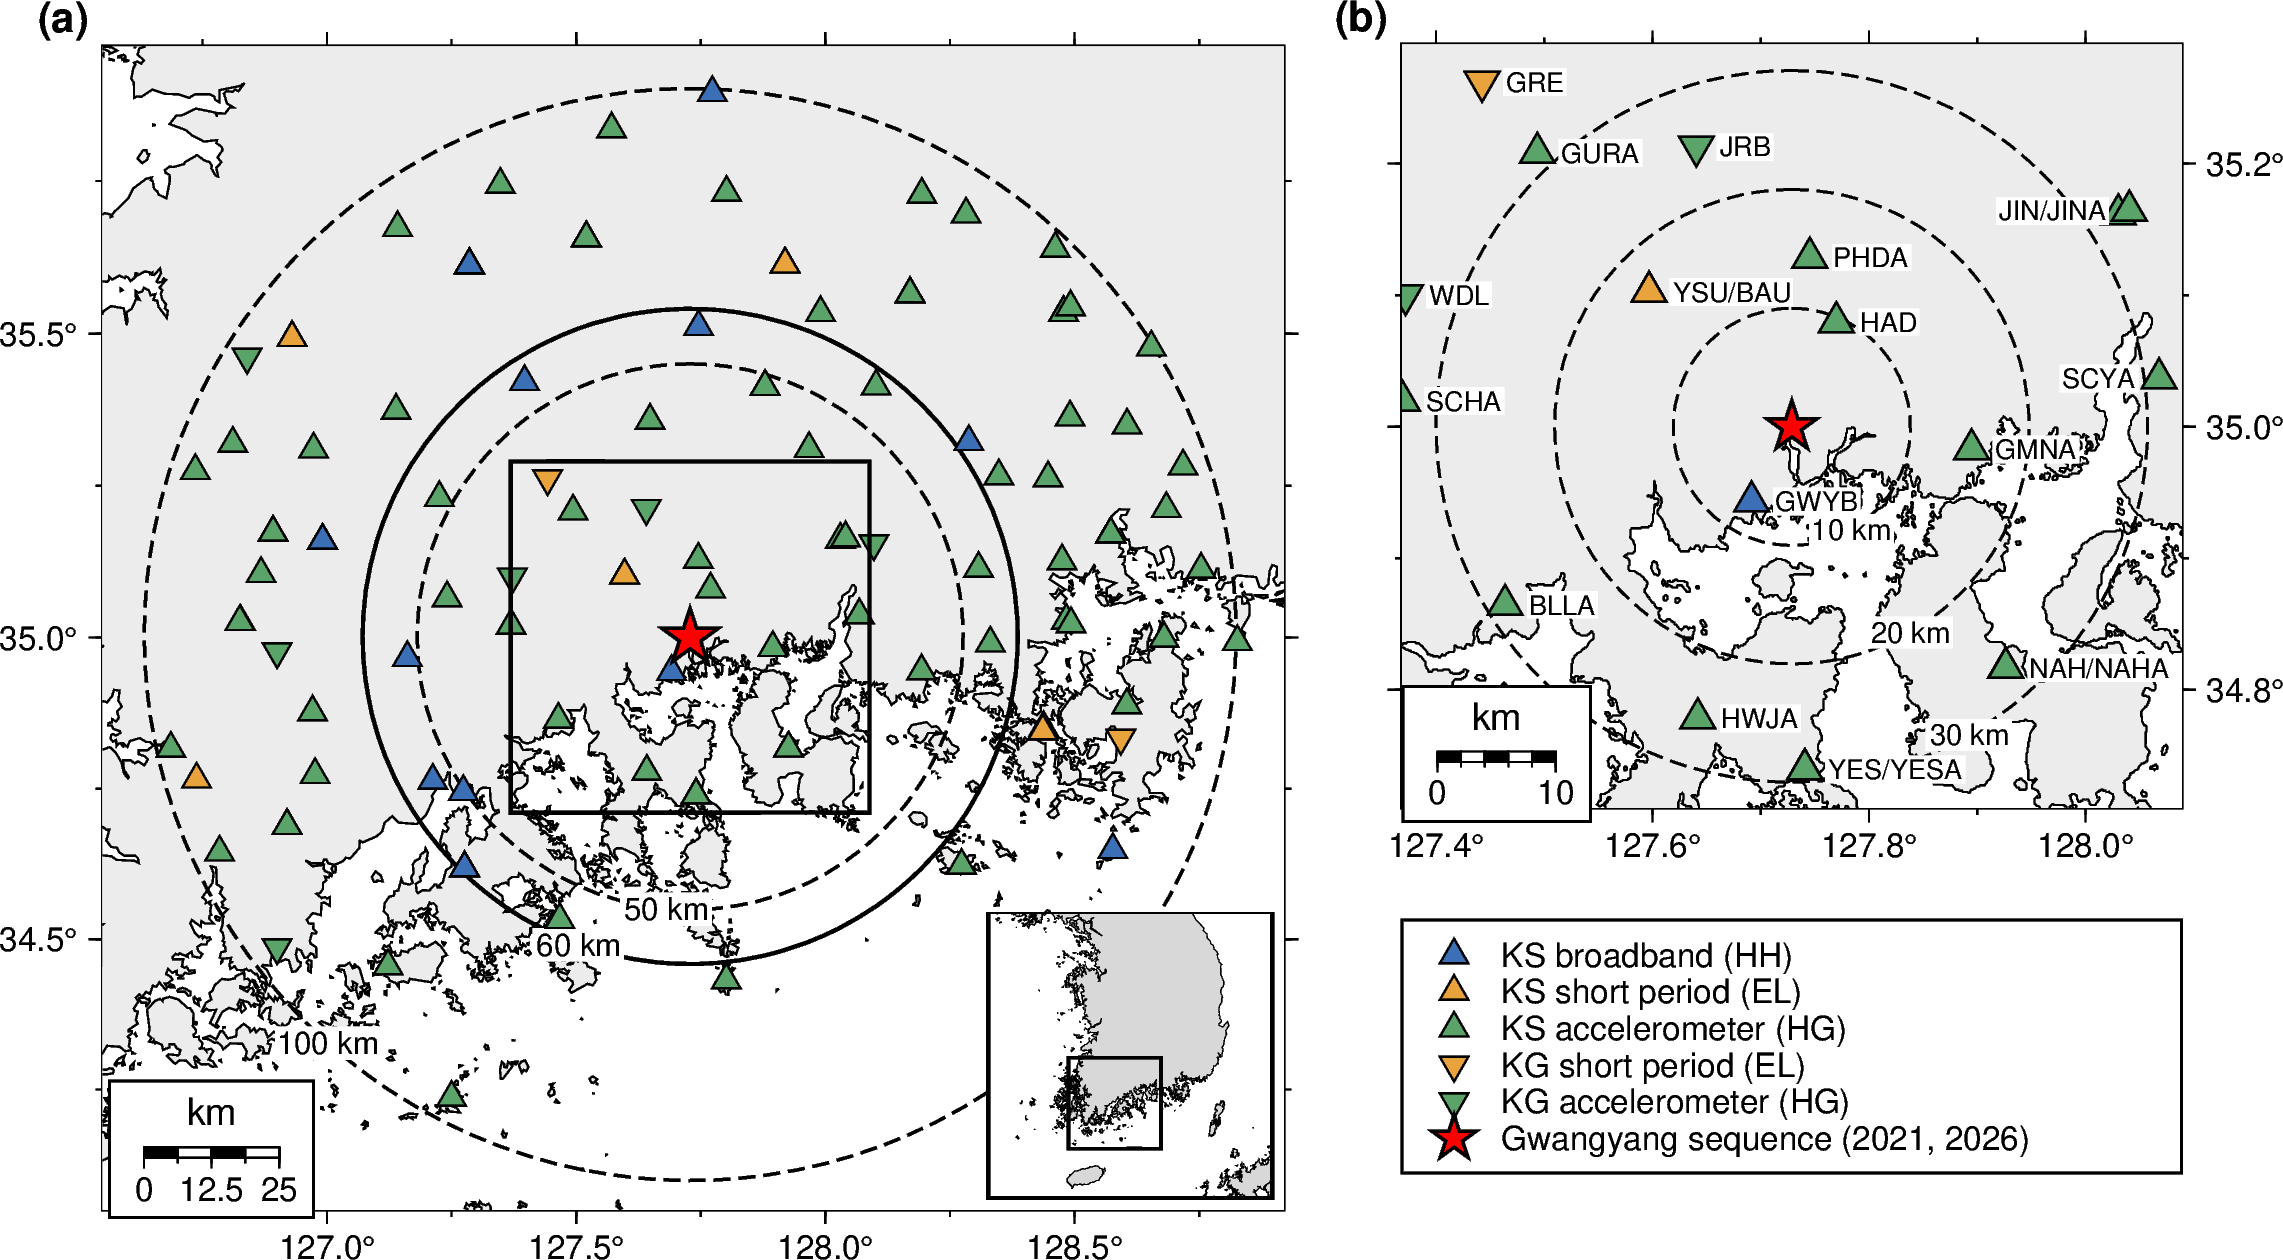

stations in panel b: GWYB 7.1 km, HAD 9.6 km, PHDA 14.4 km, GMNA 15.2 km, BAU 16.6 km, YSU 16.6 km, JRB 25.0 km, HWJA 25.9 km, NAHA 27.2 km, NAH 27.2 km, BLLA 28.4 km, YESA 29.0 km, YES 29.0 km, SCYA 31.2 km, GURA 31.5 km, JIN 32.8 km, SCHA 32.8 km, JINA 33.7 km, WDL 34.3 km, GRE 39.1 km


In [5]:
import pygmt, tempfile
from pyproj import Geod
g = Geod(ellps='WGS84'); lat0, lon0 = CEN
def ring(radius_km, n=361):
    az = np.linspace(0, 360, n); lon, lat, _ = g.fwd(np.full(n, lon0), np.full(n, lat0), az, np.full(n, radius_km * 1e3)); return lon, lat
SENS = {'HH': ('#3b6fb6', 'Broadband (HH)'), 'EL': ('#e8a33d', 'Short period (EL)'), 'HG': ('#5aa469', 'Accelerometer (HG)')}
SYM = {'KS': 't', 'KG': 'i'}
land, src_c = '#ececec', 'red'
pygmt.config(FORMAT_GEO_MAP='ddd.x', MAP_FRAME_TYPE='plain', FONT_ANNOT_PRIMARY='8p,Helvetica', FONT_LABEL='9p,Helvetica', FONT_TITLE='9p,Helvetica', MAP_FRAME_PEN='0.8p', MAP_TICK_LENGTH_PRIMARY='0.12c')
fig = pygmt.Figure()
region = [126.55, 128.92, 34.05, 35.97]
fig.basemap(region=region, projection='M10c', frame=['WSen', 'xa0.5f0.25', 'ya0.5f0.25'])
fig.coast(shorelines='0.4p,black', land=land, water='white', resolution='h')
for r_km, az_ in ((50, 185.0), (60, 200.0), (100, 222.0)):
    lon, lat = ring(r_km); fig.plot(x=lon, y=lat, pen='0.7p,black,4_2' if r_km != 60 else '0.9p,black')
    lx, ly, _ = g.fwd(lon0, lat0, az_, r_km * 1e3); fig.text(x=lx, y=ly, text=f'{r_km} km', font='7.5p,Helvetica,black', justify='CM', fill='white', clearance='0.04c/0.04c')
for (net, sen), sub in SITE.groupby(['Network', 'Sensor']):
    fig.plot(x=sub.Longitude, y=sub.Latitude, style=f'{SYM[net]}0.28c', fill=SENS[sen][0], pen='0.4p,black')
fig.plot(x=[lon0], y=[lat0], style='a0.5c', fill=src_c, pen='0.7p,black')
zoom = [lon0 - 0.36, lon0 + 0.36, lat0 - 0.29, lat0 + 0.29]
fig.plot(x=[zoom[0], zoom[1], zoom[1], zoom[0], zoom[0]], y=[zoom[2], zoom[2], zoom[3], zoom[3], zoom[2]], pen='0.9p,black')
fig.basemap(map_scale='jBL+w25k+f+o0.35c/0.35c+lkm', box='+gwhite+p0.6p,black')
with fig.inset(position='jBR+w2.4c+o0.1c/0.1c', box='+gwhite+p1.0p,black'):
    fig.coast(region=[124.5, 130.5, 33.0, 38.9], projection='M2.4c', land='#d8d8d8', water='white', shorelines='0.2p,black', resolution='i', frame=['nsew'])
    fig.plot(x=[region[0], region[1], region[1], region[0], region[0]], y=[region[2], region[2], region[3], region[3], region[2]], pen='0.8p,black')
fig.text(position='TL', text='(a)', font='10p,Helvetica-Bold', justify='BR', offset='-0.12c/0.12c', no_clip=True)
merc = lambda lat: np.log(np.tan(np.pi / 4 + np.radians(lat) / 2))
h_a = 10.0 * (merc(region[3]) - merc(region[2])) / np.radians(region[1] - region[0]); h_b = 6.6 * (merc(zoom[3]) - merc(zoom[2])) / np.radians(zoom[1] - zoom[0])
fig.shift_origin(xshift='11.0c', yshift=f'{h_a - h_b:.3f}c')
fig.basemap(region=zoom, projection='M6.6c', frame=['wSEn', 'xa0.2f0.1', 'ya0.2f0.1'])
fig.coast(shorelines='0.4p,black', land=land, water='white', resolution='f')
for r_km in (10, 20, 30):
    lon, lat = ring(r_km); fig.plot(x=lon, y=lat, pen='0.6p,black,4_2')
    lx, ly, _ = g.fwd(lon0, lat0, 150.0, r_km * 1e3); fig.text(x=lx, y=ly, text=f'{r_km} km', font='7p,Helvetica,black', justify='CM', fill='white', clearance='0.04c/0.04c')
inz = SITE[SITE.Longitude.between(zoom[0], zoom[1]) & SITE.Latitude.between(zoom[2], zoom[3])].copy()
for (net, sen), sub in inz.groupby(['Network', 'Sensor']):
    fig.plot(x=sub.Longitude, y=sub.Latitude, style=f'{SYM[net]}0.34c', fill=SENS[sen][0], pen='0.5p,black')
inz = inz.sort_values('dist_km').reset_index(drop=True); gid = [-1] * len(inz)
for i in range(len(inz)):
    if gid[i] >= 0: continue
    gid[i] = i
    for j in range(i + 1, len(inz)):
        if gid[j] < 0 and float(dist_km(inz.Latitude[j], inz.Longitude[j], inz.Latitude[i], inz.Longitude[i])) < 1.5: gid[j] = i
inz['grp'] = gid
for _, grp in inz.groupby('grp'):
    grp = grp.sort_values('Start'); r = grp.iloc[-1]; right = r.Longitude > zoom[1] - 0.14
    fig.text(x=r.Longitude, y=r.Latitude, text='/'.join(grp.Code), font='6.5p,Helvetica,black', justify='MR' if right else 'ML', offset='-0.2c/0c' if right else '0.2c/0c',
             fill='white', clearance='0.03c/0.03c')
fig.plot(x=[lon0], y=[lat0], style='a0.45c', fill=src_c, pen='0.7p,black')
fig.basemap(map_scale='jBL+w10k+f+o0.3c/0.3c+lkm', box='+gwhite+p0.6p,black')
fig.text(position='TL', text='(b)', font='10p,Helvetica-Bold', justify='BR', offset='-0.12c/0.12c', no_clip=True)
with tempfile.TemporaryDirectory() as tmp:
    spec = os.path.join(tmp, 'legend.txt')
    lines_ = [f'S 0.3c t 0.28c {SENS[s][0]} 0.4p,black 0.7c KS {SENS[s][1][0].lower() + SENS[s][1][1:]}' for s in ('HH', 'EL', 'HG')]
    lines_ += [f'S 0.3c i 0.28c {SENS[s][0]} 0.4p,black 0.7c KG {SENS[s][1][0].lower() + SENS[s][1][1:]}' for s in ('EL', 'HG')]
    lines_ += [f'S 0.3c a 0.40c {src_c} 0.7p,black 0.7c Gwangyang sequence (2021, 2026)']
    open(spec, 'w').write('\n'.join(lines_) + '\n')
    fig.legend(spec=spec, position='x0c/-0.95c+w6.6c+jTL', box='+gwhite+p0.6p,black')
fig.savefig(f'{FIG}/Figure_02_station_map.pdf'); fig.savefig(f'{FIG}/Figure_02_station_map.png', dpi=DPI)
record('Figure_02_station_map', f'{ROOT}/detection/station_table/stations.csv', f'{ROOT}/registry/streams.csv')
fig.show(width=900)
print('stations in panel b:', ', '.join(f'{r.Code} {r.dist_km:.1f} km' for r in inz.sort_values('dist_km').itertuples()))

## Figure 1: the sequence and the earlier precise relocation

(a) Every KMA-listed earthquake within 10 km of the cluster centroid since 20 December 2012 (NECIS domestic catalog, UTC). (b, c) The earlier double-difference relocation of the 11 sequence events (`gwangyang_pnplus`: PhaseNet+ picks, HypoDD with waveform cross-correlation, 1,000 bootstrap replicas); bars are bootstrap 95% half-widths.

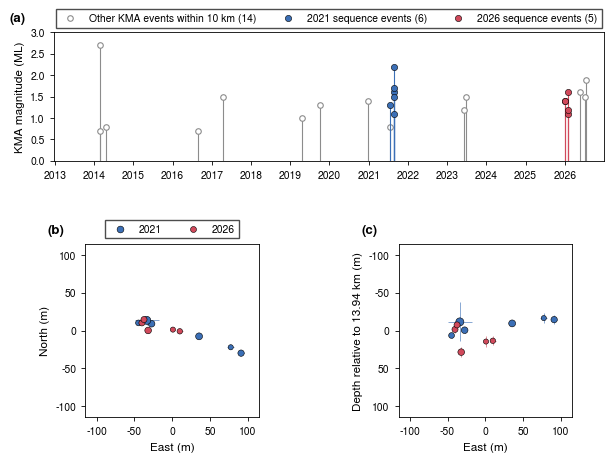

         origin_utc  magnitude  dist_km  in_seq
2014-02-21 12:17:21        2.7 5.891346   False
2014-02-21 12:52:19        0.7 5.561208   False
2014-04-22 02:21:23        0.8 8.005831   False
2016-08-26 12:36:51        0.7 9.564574   False
2017-04-16 23:10:30        1.5 9.106447   False
2019-04-22 21:10:20        1.0 3.515902   False
2019-10-05 12:04:48        1.3 7.162595   False
2020-12-28 04:17:57        1.4 8.149519   False
2021-07-20 14:38:45        0.8 7.880304   False
2021-07-20 16:14:18        1.3 0.783336    True
2021-08-27 00:23:15        1.6 0.783336    True
2021-08-27 22:03:22        2.2 0.127520    True
2021-08-28 13:34:10        1.7 1.119237    True
2021-08-28 13:39:22        1.1 2.026590    True
2021-08-28 23:45:56        1.5 0.783336    True
2023-06-03 17:47:44        1.2 5.287626   False
2023-06-26 20:24:31        1.5 3.515902   False
2026-01-01 02:49:47        1.4 1.119237    True
2026-01-01 08:48:00        1.4 0.783336    True
2026-02-02 19:41:19        1.6 0.783336 

In [6]:
C21, C26, CO = '#3b6fb6', '#d1495b', '0.55'
fig = plt.figure(figsize=(7.1, 5.0))
gs = fig.add_gridspec(2, 2, height_ratios=[1.0, 1.35], hspace=0.55, wspace=0.32)
ax = fig.add_subplot(gs[0, :])
oth = loc[~loc.in_seq]; sq = loc[loc.in_seq]
ax.vlines(oth.origin_utc, 0, oth.magnitude, color=CO, lw=0.8); ax.plot(oth.origin_utc, oth.magnitude, 'o', ms=4, mfc='white', mec=CO, mew=0.8, label=f'Other KMA events within 10 km ({len(oth)})')
for yy, cc in ((2021, C21), (2026, C26)):
    s_ = sq[sq.origin_utc.dt.year == yy]
    ax.vlines(s_.origin_utc, 0, s_.magnitude, color=cc, lw=0.8); ax.plot(s_.origin_utc, s_.magnitude, 'o', ms=4.5, color=cc, mec='k', mew=0.4, label=f'{yy} sequence events ({len(s_)})')
ax.set_xlim(pd.Timestamp(W0), pd.Timestamp('2026-12-31')); ax.set_ylim(0, 3.0); ax.set_ylabel('KMA magnitude (ML)')
ax.xaxis.set_major_locator(mdates.YearLocator(1)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=3, frameon=True, borderaxespad=0.2)
letter(ax, 'a', x=-0.05)
axm, axd = fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])
for yy, cc in ((2021, C21), (2026, C26)):
    s_ = PREV[PREV.origin_time.dt.year == yy]; sz = 12 + 18 * (s_.magnitude - 1.0)
    axm.errorbar(s_.east, s_.north, xerr=s_.ex95_m, yerr=s_.ey95_m, fmt='none', ecolor=cc, elinewidth=0.6, alpha=0.7)
    axm.scatter(s_.east, s_.north, s=sz, color=cc, edgecolor='k', linewidth=0.4, zorder=3, label=str(yy))
    axd.errorbar(s_.east, s_.depth_m - PREV.depth_m.mean(), xerr=s_.ex95_m, yerr=s_.ez95_m, fmt='none', ecolor=cc, elinewidth=0.6, alpha=0.7)
    axd.scatter(s_.east, s_.depth_m - PREV.depth_m.mean(), s=sz, color=cc, edgecolor='k', linewidth=0.4, zorder=3)
lim = 1.15 * max(PREV[['east', 'north']].abs().max().max(), (PREV.depth_m - PREV.depth_m.mean()).abs().max()) + 10
for a_ in (axm, axd): a_.set_xlim(-lim, lim); a_.set_ylim(-lim, lim); a_.set_aspect('equal'); a_.set_xlabel('East (m)')
axm.set_ylabel('North (m)'); axd.set_ylabel(f'Depth relative to {PREV.depth_km.mean():.2f} km (m)'); axd.invert_yaxis()
axm.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, borderaxespad=0.2, title=None)
letter(axm, 'b', x=-0.12); letter(axd, 'c', x=-0.12)
save(fig, 'Figure_01_sequence_background'); record('Figure_01_sequence_background', f'{ROOT}/data/catalogs/necis_events_domestic_1978_20261013.csv', PREV_CSV)
print(loc[['origin_utc', 'magnitude', 'dist_km', 'in_seq']].to_string(index=False))

## Figure 3: stations and data per year

(a) Codes within 100 km with data from their chosen sensor in each year, by sensor type (temporary codes excluded); the markers count those within 60 km (the template-matching set) and 50 km. (b) Station-days of the chosen sensors per year: on MARA (from the MARA listing of 15 October 2026) and planned from the KIGAM FDSN service (KG after 31 October 2024).

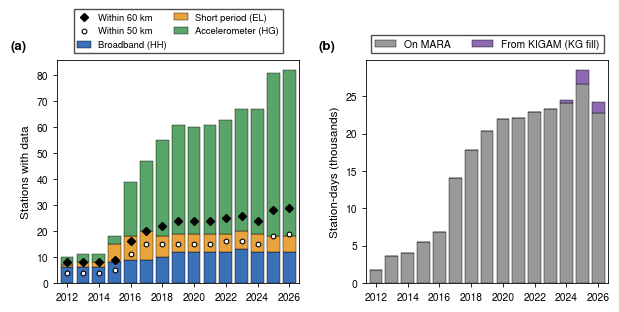

,year,HH,EL,HG,within60,within50,mara_days,kigam_days
0,2012,6,1,3,8,4,1781,0
1,2013,6,2,3,8,4,3679,0
2,2014,6,2,3,8,4,4004,0
3,2015,8,7,3,9,5,5428,0
4,2016,9,9,21,16,11,6864,0
5,2017,9,11,27,20,15,14125,0
6,2018,10,8,37,22,15,17756,0
7,2019,12,7,42,24,15,20358,0
8,2020,12,7,41,24,15,21924,0
9,2021,12,7,42,24,15,22131,0


82

In [7]:
YRS = list(range(2012, 2027))
chosen = SITE[['Network', 'Code', 'Sensor', 'dist_km']].merge(SP.drop(columns=['dist_km']), left_on=['Network', 'Code', 'Sensor'], right_on=['net', 'sta', 'sensor'], how='left')
kw_n = KW.assign(year=KW.day.dt.year).groupby(['station', 'year']).size()
cnt = {s_: [] for s_ in SENS}; c60, c50, d_mara, d_kig = [], [], [], []
for y in YRS:
    has = chosen[f'days_{y}'].fillna(0) > 0
    kg_fill = chosen.Code.map(lambda c: kw_n.get((c, y), 0)).astype(int) * (chosen.Network == 'KG')
    has_any = has | (kg_fill > 0)
    for s_ in SENS: cnt[s_].append(int((has_any & (chosen.Sensor == s_)).sum()))
    c60.append(int((has_any & (chosen.dist_km <= 60)).sum())); c50.append(int((has_any & (chosen.dist_km <= 50)).sum()))
    d_mara.append(int(chosen[f'days_{y}'].fillna(0).sum())); d_kig.append(int(kg_fill.sum()))
fig, (ax, bx) = plt.subplots(1, 2, figsize=(7.1, 2.9), gridspec_kw=dict(wspace=0.28))
bot = np.zeros(len(YRS))
for s_ in SENS:
    ax.bar(YRS, cnt[s_], bottom=bot, color=SENS[s_][0], edgecolor='k', linewidth=0.3, width=0.8, label=SENS[s_][1]); bot += np.array(cnt[s_])
ax.plot(YRS, c60, 'D', ms=3.6, color='k', label='Within 60 km'); ax.plot(YRS, c50, 'o', ms=3.4, mfc='white', mec='k', mew=0.8, label='Within 50 km')
ax.set_ylabel('Stations with data'); ax.set_xticks(YRS[::2]); ax.set_xlim(2011.4, 2026.6)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, borderaxespad=0.2, fontsize=6.8, columnspacing=0.8, handlelength=1.4)
letter(ax, 'a', x=-0.13)
bx.bar(YRS, np.array(d_mara) / 1e3, color='0.6', edgecolor='k', linewidth=0.3, width=0.8, label='On MARA')
bx.bar(YRS, np.array(d_kig) / 1e3, bottom=np.array(d_mara) / 1e3, color='#8c6bb1', edgecolor='k', linewidth=0.3, width=0.8, label='From KIGAM (KG fill)')
bx.set_ylabel('Station-days (thousands)'); bx.set_xticks(YRS[::2]); bx.set_xlim(2011.4, 2026.6)
bx.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, borderaxespad=0.2)
letter(bx, 'b', x=-0.13)
save(fig, 'Figure_03_data_per_year'); record('Figure_03_data_per_year', f'{ROOT}/docs/station_inventory/tables/stream_periods.csv', f'{ROOT}/data/continuous/KG_kigam_fdsn_sds/_manifest/worklist.csv')
TAB3 = pd.DataFrame(dict(year=YRS, HH=cnt['HH'], EL=cnt['EL'], HG=cnt['HG'], within60=c60, within50=c50, mara_days=d_mara, kigam_days=d_kig)); display(TAB3)
fact('data.sd_mara', f'{sum(d_mara):,}', 'stream_periods.csv', 'station-days of the chosen sensors on MARA'); fact('data.sd_kigam', f'{sum(d_kig):,}', 'KIGAM worklist')
fact('data.n100_2013', int(TAB3.set_index('year').loc[2013, ['HH', 'EL', 'HG']].sum()), 'Figure 3'); fact('data.n100_2021', int(TAB3.set_index('year').loc[2021, ['HH', 'EL', 'HG']].sum()), 'Figure 3')
fact('data.n100_max', int(TAB3[['HH', 'EL', 'HG']].sum(axis=1).max()), 'Figure 3')

## Figure 4: completeness of the 2021 episode data

For every chosen sensor with data between 1 July and 30 September 2021, each day of the continuous link tree is classified: all three components from MARA; all three present with at least one re-fetched from NECIS (decision G-D13); a component missing; no data. Triangles mark the days of the six KMA-listed 2021 events.

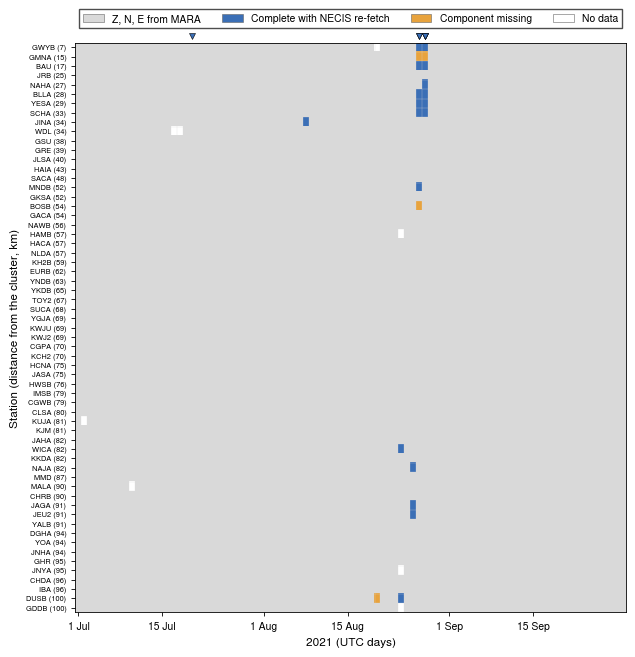

{'MARA complete': 5582, 'with NECIS': 18, 'partial': 4, 'no data': 8, 'outside span': 0}


In [8]:
LINK = f'{ROOT}/data/continuous/sds_links'
days = pd.date_range('2021-07-01', '2021-09-30'); D0, D1 = days[0].strftime('%Y-%m-%d'), days[-1].strftime('%Y-%m-%d')
rows_ = SITE[(SITE.Start <= D1) & (SITE['last'] >= D0)].sort_values('dist_km').reset_index(drop=True)
M = np.zeros((len(rows_), len(days)), int)
for i, r in rows_.iterrows():
    for j, d in enumerate(days):
        if not (r.Start <= d.strftime('%Y-%m-%d') <= r['last']): M[i, j] = -1; continue
        n_ok = n_nec = 0
        for c in 'ZNE':
            p = f'{LINK}/{r.Network}/{r.Code}/{r.Sensor}{c}.D/{r.Network}.{r.Code}..{r.Sensor}{c}.D.{d.year}.{d.dayofyear:03d}'
            if os.path.lexists(p):
                n_ok += 1; n_nec += 'necis_refetch' in os.readlink(p)
        M[i, j] = 3 if (n_ok == 3 and n_nec == 0) else 2 if n_ok == 3 else 1 if n_ok else 0
cm4 = ListedColormap(['white', '#ffffff', '#e8a33d', '#3b6fb6', '#d9d9d9'])
fig, ax = plt.subplots(figsize=(7.1, 7.4))
ax.imshow(M + 1, cmap=cm4, vmin=-0.5, vmax=4.5, aspect='auto', interpolation='nearest')
ax.set_yticks(range(len(rows_))); ax.set_yticklabels([f'{r.Code} ({r.dist_km:.0f})' for r in rows_.itertuples()], fontsize=5.4)
tk = [j for j, d in enumerate(days) if d.day in (1, 15)]
ax.set_xticks(tk); ax.set_xticklabels([days[j].strftime('%-d %b') for j in tk])
ax.set_xticks(np.arange(-0.5, len(days), 1), minor=True); ax.set_yticks(np.arange(-0.5, len(rows_), 1), minor=True)
ax.grid(which='minor', color='0.85', lw=0.2); ax.tick_params(which='minor', length=0)
for t in ev21.origin_time_utc:
    j = (t.normalize() - days[0]).days; ax.plot(j, -1.2, 'v', color=C21, mec='k', mew=0.4, ms=5, clip_on=False)
ax.set_ylim(len(rows_) - 0.5, -0.5); ax.set_xlabel('2021 (UTC days)'); ax.set_ylabel('Station (distance from the cluster, km)')
hand = [Patch(fc='#d9d9d9', ec='0.4', lw=0.4, label='Z, N, E from MARA'), Patch(fc='#3b6fb6', ec='0.4', lw=0.4, label='Complete with NECIS re-fetch'),
        Patch(fc='#e8a33d', ec='0.4', lw=0.4, label='Component missing'), Patch(fc='white', ec='0.4', lw=0.4, label='No data')]
ax.legend(handles=hand, loc='lower center', bbox_to_anchor=(0.5, 1.015), ncol=4, frameon=True, borderaxespad=0.6)
save(fig, 'Figure_04_episode_2021_completeness'); record('Figure_04_episode_2021_completeness', f'{ROOT}/docs/station_inventory/tables/component_audit_2021_2026.csv', f'{ROOT}/logs/necis_refetch_jobs_20261015.csv')
vals = M[M >= 0]
fact('f4.nsta', len(rows_), 'link tree', 'chosen sensors with data in Jul-Sep 2021'); fact('f4.pct', f'{100 * (vals == 3).mean() + 100 * (vals == 2).mean():.1f}', 'link tree', '% station-days complete')
fact('f4.n_nec', int((M == 2).sum()), 'link tree', 'station-days complete only with NECIS'); fact('f4.n_part', int((M == 1).sum()), 'link tree'); fact('f4.n_none', int((M == 0).sum()), 'link tree')
print({k: int((M == v).sum()) for k, v in (('MARA complete', 3), ('with NECIS', 2), ('partial', 1), ('no data', 0), ('outside span', -1))})

## Figure 5: sensor orientation

(a) KS.GWYB broadband (7 km from the cluster): the misorientation measured on each teleseism (P_minT estimator of Seo et al. 2022, accepted measurements) and the four periods of the dated orientation table. (b) The periods of every chosen sensor within 60 km, colored by angle; gray lines are the data spans; a gap between periods is a change bracket (no angle assigned there). (c) The same events measured from the local day files (G2) and from the national study's server windows (33): absolute difference of the accepted angles.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


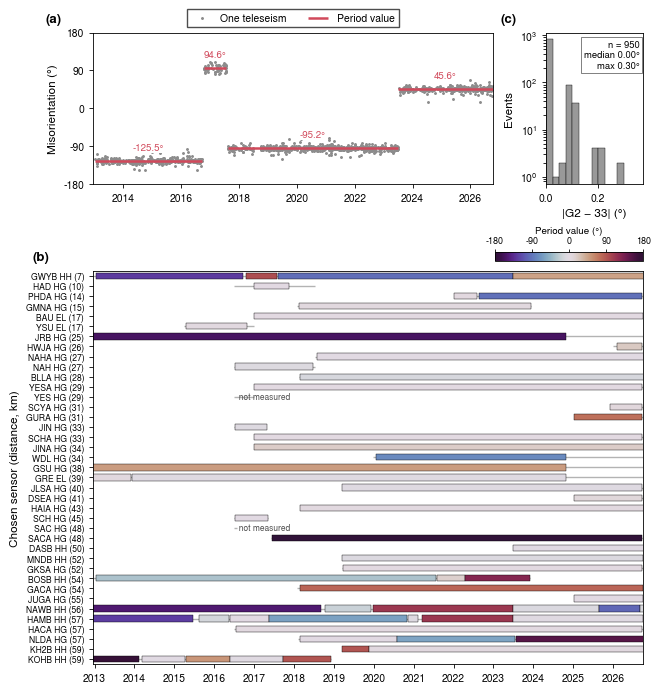

chosen sensors within 60 km and their number of periods: {'GWYB': 4, 'HAD': 1, 'PHDA': 2, 'GMNA': 1, 'BAU': 1, 'YSU': 1, 'JRB': 1, 'HWJA': 1, 'NAHA': 1, 'NAH': 1, 'BLLA': 1, 'YESA': 1, 'YES': 0, 'SCYA': 1, 'GURA': 1, 'JIN': 1, 'SCHA': 1, 'JINA': 1, 'WDL': 1, 'GSU': 1, 'GRE': 2, 'JLSA': 1, 'DSEA': 1, 'HAIA': 1, 'SCH': 1, 'SAC': 0, 'SACA': 1, 'DASB': 1, 'MNDB': 1, 'GKSA': 1, 'BOSB': 3, 'GACA': 1, 'JUGA': 1, 'NAWB': 6, 'HAMB': 7, 'HACA': 1, 'NLDA': 3, 'KH2B': 2, 'KOHB': 5}


In [9]:
N33 = '/home/msseo/works/33.KS_station_orientation/national/Table/measurements_all.csv'
parts = [c[(c.unit == 'GWYB.HH') & c.ok_mint.astype(str).eq('True')] for c in pd.read_csv(N33, usecols=['unit', 'event', 'time', 'mis_mint', 'ok_mint'], chunksize=500_000)]
g33 = pd.concat(parts); r1c = pd.read_csv(f'{ROOT}/data/stations/orientation_r1c/Table/measurements_r1c.csv', usecols=['unit', 'event', 'time', 'mis_mint', 'ok_mint'])
r1c = r1c[(r1c.unit == 'GWYB.HH') & r1c.ok_mint.astype(str).eq('True') & ~r1c.event.isin(g33.event)]
gm = pd.concat([g33.assign(src='33'), r1c.assign(src='G2')]); gm['time'] = pd.to_datetime(gm.time)
for r in gw.itertuples():
    s_ = gm[(gm.time >= r.start) & (gm.time <= pd.Timestamp(r.end) + pd.Timedelta(days=1))]
    dd = ((s_.mis_mint - r.theta_M_apply + 180) % 360 - 180).median(); assert abs(dd) < 3, (r.start, dd)
fact('gwyb.n_ev', f'{len(gm):,}', 'measurements_all.csv + measurements_r1c.csv', 'accepted GWYB.HH measurements'); fact('gwyb.n_new', len(r1c), 'measurements_r1c.csv')
cmap5 = mpl.colormaps['twilight_shifted']; norm5 = Normalize(-180, 180)
fig = plt.figure(figsize=(7.1, 8.2))
gs = fig.add_gridspec(2, 4, height_ratios=[1.0, 2.6], hspace=0.32, wspace=0.55)
ax = fig.add_subplot(gs[0, :3]); cx = fig.add_subplot(gs[0, 3]); bx = fig.add_subplot(gs[1, :])
ax.plot(gm.time, gm.mis_mint, '.', ms=2.2, color='0.55', label='One teleseism')
for r in gw.itertuples():
    ax.hlines(r.theta_M_apply, pd.Timestamp(r.start), pd.Timestamp(r.end), color='#d1495b', lw=1.8, label='Period value' if r.Index == 0 else None)
    ax.text(pd.Timestamp(r.start) + (pd.Timestamp(r.end) - pd.Timestamp(r.start)) / 2, r.theta_M_apply + 22, f'{r.theta_M_apply:.1f}°', ha='center', va='bottom', fontsize=7, color='#d1495b',
            bbox=dict(fc='white', ec='none', pad=0.6))
ax.set_ylim(-180, 180); ax.set_yticks([-180, -90, 0, 90, 180]); ax.set_ylabel('Misorientation (°)'); ax.set_xlim(pd.Timestamp(W0), pd.Timestamp(W1))
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(loc='lower center', bbox_to_anchor=(0.5, 1.02), ncol=2, frameon=True, borderaxespad=0.2); letter(ax, 'a', x=-0.08)
cx.hist(CHK['diff'], bins=np.arange(0, 0.40, 0.025), color='0.6', edgecolor='k', linewidth=0.3)
cx.set_xlabel('|G2 − 33| (°)'); cx.set_ylabel('Events'); cx.set_yscale('log'); cx.set_xlim(0, 0.375)
cx.text(0.96, 0.95, f'n = {len(CHK)}\nmedian {CHK["diff"].median():.2f}°\nmax {CHK["diff"].max():.2f}°', transform=cx.transAxes, ha='right', va='top', fontsize=6.8, bbox=dict(fc='white', ec='0.3', lw=0.5, pad=2))
letter(cx, 'c', x=-0.3)
sel = SITE[SITE.dist_km <= 60].sort_values('dist_km').reset_index(drop=True)
for i, r in sel.iterrows():
    bx.hlines(i, pd.Timestamp(max(r.Start, W0)), pd.Timestamp(min(r['last'], W1)), color='0.7', lw=1.0, zorder=1)
    ps = OP[(OP.net == r.Network) & (OP.sta == r.Code) & (OP.sensor == r.Sensor)]
    for p in ps.itertuples():
        t0_, t1_ = mdates.date2num(pd.Timestamp(p.start)), mdates.date2num(pd.Timestamp(p.end) + pd.Timedelta(days=1))
        bx.barh(i, t1_ - t0_, left=t0_, height=0.62, color=cmap5(norm5(p.theta_M_apply)), edgecolor='k', linewidth=0.3, zorder=2)
    if not len(ps): bx.text(pd.Timestamp(max(r.Start, W0)), i, '  not measured', va='center', fontsize=6, color='0.3')
bx.set_yticks(range(len(sel))); bx.set_yticklabels([f'{r.Code} {r.Sensor} ({r.dist_km:.0f})' for r in sel.itertuples()], fontsize=6.2)
bx.set_ylim(len(sel) - 0.5, -0.5); bx.set_xlim(pd.Timestamp(W0), pd.Timestamp(W1))
bx.xaxis.set_major_locator(mdates.YearLocator(1)); bx.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
bx.set_ylabel('Chosen sensor (distance, km)'); letter(bx, 'b', x=-0.08)
cax = bx.inset_axes([0.73, 1.025, 0.27, 0.022]); cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm5, cmap=cmap5), cax=cax, orientation='horizontal')
cb.set_ticks([-180, -90, 0, 90, 180]); cb.ax.tick_params(labelsize=6.5, length=2); cb.ax.xaxis.set_ticks_position('top'); cb.set_label('Period value (°)', fontsize=7, labelpad=2); cb.ax.xaxis.set_label_position('top')
save(fig, 'Figure_05_orientation'); record('Figure_05_orientation', f'{ROOT}/docs/station_inventory/tables/orientation_periods.csv', N33, f'{ROOT}/data/stations/orientation_r1c/Table/measurements_r1c.csv', f'{ROOT}/data/stations/orientation_r1c/Table/check_local_vs_stp.csv')
print('chosen sensors within 60 km and their number of periods:', dict(zip(sel.Code, [int(((OP.net == r.Network) & (OP.sta == r.Code) & (OP.sensor == r.Sensor)).sum()) for r in sel.itertuples()])))

## Figure 6: processing stages

Status as of this notebook's run. A pilot run on 2021 and 2026 (folder `pilot/`) exercises G4-G7 before the production run; nothing in it is used by the production stages.

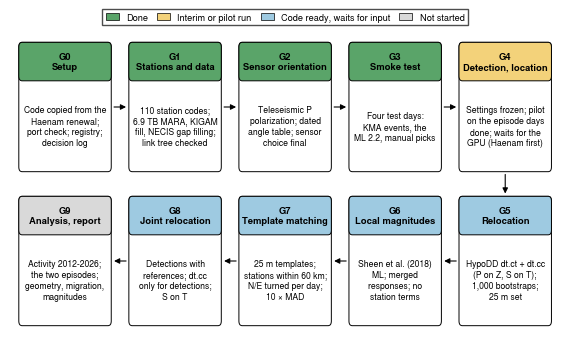

In [10]:
STAGES = [('G0', 'Setup', 'Code copied from the\nHaenam renewal;\nport check; registry;\ndecision log', 'done'),
          ('G1', 'Stations and data', f'{len(SITE)} station codes;\n6.9 TB MARA, KIGAM\nfill, NECIS gap filling;\nlink tree checked', 'done'),
          ('G2', 'Sensor orientation', 'Teleseismic P\npolarization; dated\nangle table; sensor\nchoice final', 'done'),
          ('G3', 'Smoke test', 'Four test days:\nKMA events, the\nML 2.2, manual picks', 'done'),
          ('G4', 'Detection, location', 'Settings frozen; pilot\non the episode days\ndone; waits for the\nGPU (Haenam first)', 'interim'),
          ('G5', 'Relocation', 'HypoDD dt.ct + dt.cc\n(P on Z, S on T);\n1,000 bootstraps;\n25 m set', 'prepared'),
          ('G6', 'Local magnitudes', 'Sheen et al. (2018)\nML; merged\nresponses; no\nstation terms', 'prepared'),
          ('G7', 'Template matching', '25 m templates;\nstations within 60 km;\nN/E turned per day;\n10 × MAD', 'prepared'),
          ('G8', 'Joint relocation', 'Detections with\nreferences; dt.cc\nonly for detections;\nS on T', 'prepared'),
          ('G9', 'Analysis, report', 'Activity 2012-2026;\nthe two episodes;\ngeometry, migration,\nmagnitudes', 'pending')]
SC = {'done': ('#5aa469', 'Done'), 'running': ('#e8a33d', 'Running'), 'interim': ('#f3d27a', 'Interim or pilot run'),
      'prepared': ('#9ecae1', 'Code ready, waits for input'), 'pending': ('#d9d9d9', 'Not started')}
fig, ax = plt.subplots(figsize=(7.1, 4.0)); ax.set_xlim(0, 5); ax.set_ylim(0, 2); ax.axis('off')
pos = {STAGES[i][0]: (i, 1) for i in range(5)}
pos.update({STAGES[i][0]: (9 - i, 0) for i in range(5, 10)})
W_, H_, HC = 0.84, 0.84, 0.25
for k, name, desc, stt in STAGES:
    x, y = pos[k]; x0, y0 = x + (1 - W_) / 2, y + (1 - H_) / 2
    ax.add_patch(FancyBboxPatch((x0, y0), W_, H_, boxstyle='round,pad=0.0,rounding_size=0.03', fc='white', ec='k', lw=0.7))
    ax.add_patch(FancyBboxPatch((x0, y0 + H_ - HC), W_, HC, boxstyle='round,pad=0.0,rounding_size=0.03', fc=SC[stt][0], ec='k', lw=0.7))
    ax.text(x + 0.5, y0 + H_ - HC / 2, f'{k}\n{name}', ha='center', va='center', fontsize=6.8, fontweight='bold', linespacing=1.15)
    ax.text(x + 0.5, y0 + (H_ - HC) / 2, desc, ha='center', va='center', fontsize=6.2, linespacing=1.3)
order = [k for k, *_ in STAGES]
for a_, b_ in zip(order[:-1], order[1:]):
    (xa, ya), (xb, yb) = pos[a_], pos[b_]
    if ya == yb:
        s = 1 if xb > xa else -1
        ax.annotate('', xy=(xb + 0.5 - s * W_ / 2, yb + 0.5), xytext=(xa + 0.5 + s * W_ / 2, ya + 0.5), arrowprops=dict(arrowstyle='-|>', lw=0.8, color='k', mutation_scale=8))
    else:
        ax.annotate('', xy=(xb + 0.5, yb + 0.5 + H_ / 2), xytext=(xa + 0.5, ya + 0.5 - H_ / 2), arrowprops=dict(arrowstyle='-|>', lw=0.8, color='k', mutation_scale=8))
used_ = [k for k in SC if k in {st for *_, st in STAGES}]
ax.legend(handles=[Patch(fc=SC[k][0], ec='k', lw=0.5, label=SC[k][1]) for k in used_], loc='lower center', bbox_to_anchor=(0.5, 1.0), ncol=len(used_), frameon=True, fontsize=6.6, columnspacing=1.0, handlelength=1.4)
save(fig, 'Figure_06_stages')

## Write facts.json, facts.tex, the decision table and the figure sources

In [11]:
def ltx(s):
    s = str(s)
    for a_, b_ in (('&', r'\&'), ('%', r'\%'), ('_', r'\_'), ('#', r'\#'), ('$', r'\$'), ('{', r'\{'), ('}', r'\}'), ('~', r'\textasciitilde{}'), ('^', r'\textasciicircum{}'), ('->', r'$\rightarrow$'), ('<=', r'$\leq$'), ('>=', r'$\geq$')):
        s = s.replace(a_, b_)
    return s
def _key(i):
    m_ = re.match(r'([A-Z]+(?:-D)?)(\d+)(.*)$', DEC.id[i]); assert m_, DEC.id[i]; g_ = {'P': 0, 'R': 1, 'G-D': 2}.get(m_.group(1), 3)
    return (g_, int(m_.group(2)), m_.group(3))
order_ = sorted(DEC.index, key=_key)
rows_tex = [rf'{ltx(DEC.id[i])} & {ltx(DEC.setting[i])} & {ltx(DEC.gwangyang_value[i])} & {ltx(DEC.status[i])} \\' for i in order_]
head_ = [r'\begin{longtable}{@{}p{1.0cm}>{\raggedright\arraybackslash}p{3.4cm}>{\raggedright\arraybackslash}p{8.6cm}p{1.8cm}@{}}', r'\toprule', r'ID & Setting & Gwangyang value & Status \\', r'\midrule', r'\endhead']
open(f'{REP}/tab_decisions.tex', 'w').write('% written by notebooks/90_study_plan_report.ipynb from docs/decisions.csv; do not edit by hand\n' + '\n'.join(head_ + rows_tex + [r'\bottomrule', r'\end{longtable}']) + '\n')
meta = dict(generated=datetime.datetime.now().astimezone().isoformat(timespec='seconds'), notebook=f'{NBD}/90_study_plan_report.ipynb', project_root=ROOT, n_facts=len(FACTS))
json.dump(dict(meta=meta, facts=FACTS), open(f'{REP}/facts.json', 'w'), indent=1, ensure_ascii=False)
lines = ['% facts.tex -- written by notebooks/90_study_plan_report.ipynb from facts.json; do not edit by hand.', f'% generated {meta["generated"]}; {len(FACTS)} macros.',
         r'\makeatletter', r'\newcommand\FactDef[2]{\expandafter\def\csname fact@#1\endcsname{#2}}',
         r'\DeclareRobustCommand\F[1]{\ifcsname fact@#1\endcsname\csname fact@#1\expandafter\endcsname\else\PackageError{facts}{Undefined fact #1}{Add it to notebook 90}\fi}', r'\makeatother']
lines += [rf'\FactDef{{{k}}}{{{v["value"]}}}' for k, v in sorted(FACTS.items())]
open(f'{REP}/facts.tex', 'w').write('\n'.join(lines) + '\n')
json.dump(SOURCES, open(f'{FIG}/sources.json', 'w'), indent=1)
figs = sorted(glob.glob(f'{FIG}/Figure_*.pdf')); print(f'{len(FACTS)} facts -> facts.json / facts.tex; {len(rows_tex)} decision rows -> tab_decisions.tex; {len(figs)} figures:', ', '.join(os.path.basename(f) for f in figs))

141 facts -> facts.json / facts.tex; 34 decision rows -> tab_decisions.tex; 12 figures: Figure_01_sequence_background.pdf, Figure_02_station_map.pdf, Figure_03_data_per_year.pdf, Figure_04_episode_2021_completeness.pdf, Figure_05_orientation.pdf, Figure_06_stages.pdf, Figure_07_pilot_locations_relative.pdf, Figure_08_pilot_locations_absolute.pdf, Figure_09_pilot_waveforms.pdf, Figure_10_pilot_same_patch.pdf, Figure_11_pilot_magnitudes.pdf, Figure_12_pilot_timeline.pdf


## Comprehensive summary

In [12]:
F = lambda k: FACTS[k]['value']
S = pd.DataFrame([
    ('Figures written (PDF + PNG, 300 dpi)', f'{len(figs)}: ' + ', '.join(os.path.basename(f)[:-4] for f in figs)),
    ('Facts written', f'{len(FACTS)} (computed here: {sum(not v["source"].startswith("notebooks/") for v in FACTS.values())}; quoted from executed notebooks: {sum(v["source"].startswith("notebooks/") for v in FACTS.values())})'),
    ('Sequence', f'{F("seq.n")} KMA events (2021: {F("seq.n21")}, 2026: {F("seq.n26")}), ML {F("seq.ml")}; other KMA events within 10 km since 2012-12-20: {F("kma.n10_other")}'),
    ('Stations', f'{F("sta.n")} codes ({F("sta.n_ks")} KS, {F("sta.n_kg")} KG); within 60 km: {F("sta.n60_2013")} in 2013, {F("sta.n60_2021")} in 2021'),
    ('2021 episode data', f'{F("f4.pct")}% of station-days complete; {F("f4.n_nec")} complete only with NECIS; {F("f4.n_part")} partial'),
    ('Orientation', f'GWYB four periods {F("gwyb.t1")}, {F("gwyb.t2")}, {F("gwyb.t3")}, {F("gwyb.t4")} deg; local vs national median {F("chk.med")} deg (n {F("chk.n")})'),
    ('Status snapshot', f'{F("stat.time")}: MARA {F("stat.pull_done")}/{F("stat.pull_tot")} station-years ({F("stat.pull_tb")} TB); KIGAM {F("stat.kigam_files")} files, {F("stat.kigam_err")} errors; freeze {F("stat.freeze")}'),
], columns=['quantity', 'value']); display(S)
print('Take-homes:')
print('1. The six figures are drawn from the project tables only; their PDF and PNG files and input checksums (figures/sources.json) are in the report folder.')
print('2. Every number the report quotes is a macro from facts.tex; the appendix decision table is written from docs/decisions.csv, so a re-run keeps the report current.')
print('3. Rebuild: re-run this notebook, then compile report.tex with tectonic (see the report README).')

,quantity,value
0,"Figures written (PDF + PNG, 300 dpi)","12: Figure_01_sequence_background, Figure_02_station_map, Figure_03_data_per_year, Figure_04_episode_2021_completeness, Figure_05_orientation, Figure_06_sta..."
1,Facts written,141 (computed here: 131; quoted from executed notebooks: 10)
2,Sequence,"11 KMA events (2021: 6, 2026: 5), ML 1.1–2.2; other KMA events within 10 km since 2012-12-20: 14"
3,Stations,"110 codes (102 KS, 8 KG); within 60 km: 8 in 2013, 24 in 2021"
4,2021 episode data,99.8% of station-days complete; 18 complete only with NECIS; 4 partial
5,Orientation,"GWYB four periods −125.5, +94.6, −95.2, +45.6 deg; local vs national median 0.00 deg (n 950)"
6,Status snapshot,"2026-10-16 16:40 KST: MARA 760/760 station-years (6.9 TB); KIGAM 10,629 files, 0 errors; freeze d724acfddcd608dd"


Take-homes:
1. The six figures are drawn from the project tables only; their PDF and PNG files and input checksums (figures/sources.json) are in the report folder.
2. Every number the report quotes is a macro from facts.tex; the appendix decision table is written from docs/decisions.csv, so a re-run keeps the report current.
3. Rebuild: re-run this notebook, then compile report.tex with tectonic (see the report README).
